In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [3]:
sns.set_theme(style="whitegrid", context="talk")

In [4]:
PALETTE_8 = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
HIGHLIGHT, HIGHLIGHT_COLOR = 't_satclip', '#FF00AA'

In [5]:
def color_map(models):
    others = [m for m in models if m != HIGHLIGHT]
    cmap = {m: PALETTE_8[i % len(PALETTE_8)] for i, m in enumerate(others)}
    cmap[HIGHLIGHT] = HIGHLIGHT_COLOR
    return cmap

In [6]:
def bold_highlight(tick_labels):
    for lbl in tick_labels:
        if lbl.get_text() == HIGHLIGHT:
            lbl.set_fontweight('bold')

# Comparison on DM-US_trees

Daily timestamps

In [15]:
# df = pd.read_csv('/home/libe2152/projects/torchgeo-bench/results/coordbench_results.csv')
df = pd.read_csv('/home/leca5365/Documents/torchgeo-bench-temporal-dev/src/torchgeo_bench/coordbench/scripts/results/coordbench_chelsa_spatiotemporal_encoders_aggregated_embeddings.csv')
df = df.drop_duplicates(subset=['dataset', 'task', 'method', 'split', 'model_name'], keep='last')

sub = df[df['dataset'] == 'dm-us_trees']
MODEL_ORDER = sorted(sub['model_name'].unique())
MODEL_COLORS = color_map(MODEL_ORDER)
SPLITS = ['random', 'spatial']

In [16]:
def plot_method(method, title):
    fig, axes = plt.subplots(1, len(SPLITS), figsize=(13, 5), sharey=True)
    for ax, split in zip(axes, SPLITS):
        m_df = sub[(sub['method'] == method) & (sub['split'] == split)].set_index('model_name').reindex(MODEL_ORDER)
        x = np.arange(len(MODEL_ORDER))
        yerr = (m_df['ci_upper'] - m_df['ci_lower']) / 2
        ax.bar(x, m_df['metric_value'], yerr=yerr, capsize=3, color=[MODEL_COLORS[m] for m in MODEL_ORDER])
        ax.set_xticks(x)
        bold_highlight(ax.set_xticklabels(MODEL_ORDER, rotation=30, ha='right'))
        ax.set_title(f'{split} split')
        ax.set_xlabel('Model')
    axes[0].set_ylabel('Accuracy')
    handles = [plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[m]) for m in MODEL_ORDER]
    axes[-1].legend(handles, MODEL_ORDER, bbox_to_anchor=(1.02, 1), loc='upper left', title='Model')
    fig.suptitle(f'us_trees - {title}', y=1.02)
    plt.tight_layout()
    return fig

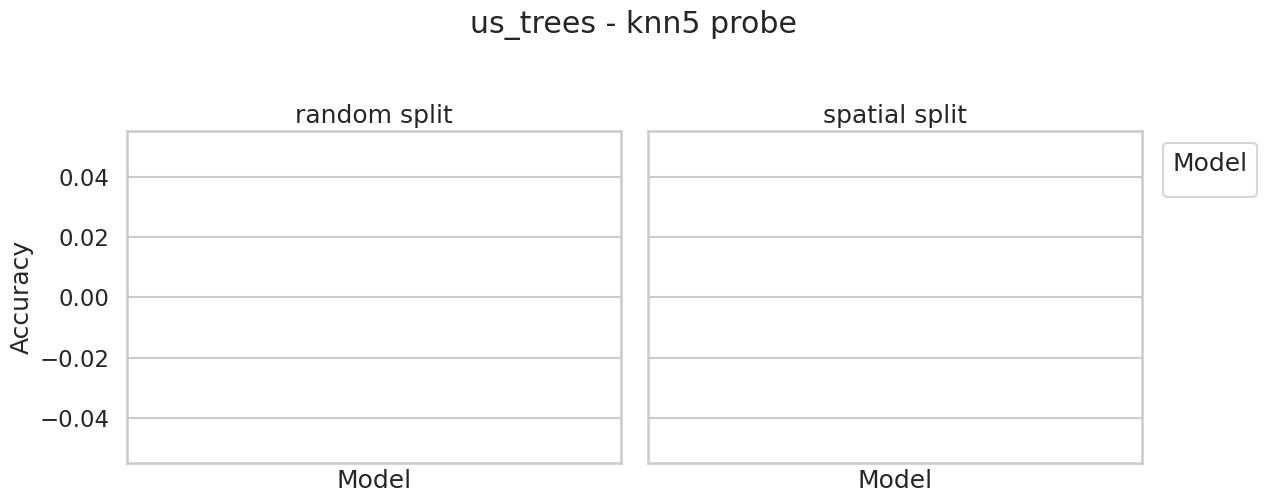

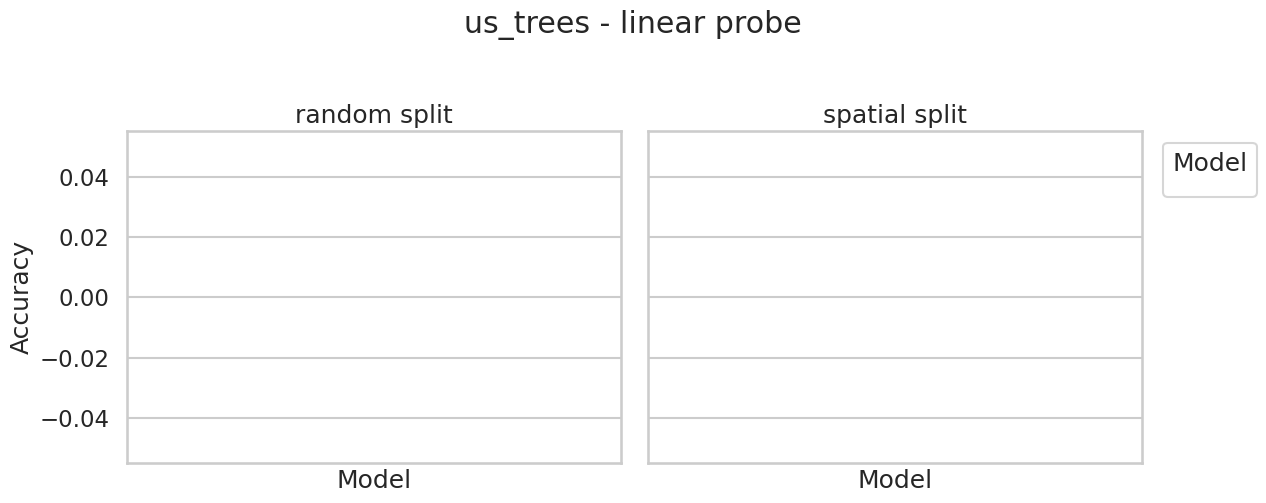

In [17]:
plot_method('knn5', 'knn5 probe'); plt.show()
plot_method('linear', 'linear probe'); plt.show()

# Comparison on Elevation (no timestamps) data

Currently, t-SatCLIP embeddings per month are extracted and then averaged to estimate an annual mean embedding

In [ ]:
df = pd.read_csv('/home/libe2152/projects/torchgeo-bench/results/coordbench_results_old.csv')
df = df.drop_duplicates(subset=['dataset', 'task', 'method', 'split', 'model_name', 'embedding_aggregation'], keep='last')

sub = df[(df['dataset'] == 'satclip-elevation') & (df['method'] == 'linear')]
MODEL_ORDER = sorted(sub['model_name'].unique())
MODEL_COLORS = color_map(MODEL_ORDER)

AGG_ORDER = ['none', 'none:default_date=2019-01-01', 'none:default_date=2019-08-01', 'summer:2019:MS', 'yearly:2019:MS']
# short text tag under each bar instead of a color/shading/hatch code - just read the label
AGG_SHORT = {
    'none': 'static',
    'none:default_date=2019-01-01': 'Jan',
    'none:default_date=2019-08-01': 'Aug',
    'summer:2019:MS': 'summer',
    'yearly:2019:MS': 'annual',
}

In [ ]:
def plot_split(split):
    split_df = sub[sub['split'] == split]
    fig, ax = plt.subplots(figsize=(9, 6.5))

    slot = 0
    xticks, xticklabels = [], []
    for model in MODEL_ORDER:
        m_df = split_df[split_df['model_name'] == model]
        if m_df.empty:
            continue  # this model has no result for this split
        aggs_present = [a for a in AGG_ORDER if a in m_df['embedding_aggregation'].values]
        n = len(aggs_present)
        width = 0.8 / max(n, 1)
        centers = slot + (np.arange(n) - (n - 1) / 2) * width
        for c, agg in zip(centers, aggs_present):
            row = m_df[m_df['embedding_aggregation'] == agg].iloc[0]
            yerr = (row['ci_upper'] - row['ci_lower']) / 2
            ax.bar(c, row['metric_value'], width * 0.9, yerr=yerr, capsize=2,
                   color=MODEL_COLORS[model], edgecolor='white', linewidth=0.6)
            if n > 1:
                # only label bars where there's actually more than one aggregation to tell apart
                ax.text(c, -0.02, AGG_SHORT[agg], rotation=90, fontsize=9,
                        ha='center', va='top', transform=ax.get_xaxis_transform())
        xticks.append(slot)
        xticklabels.append(model)
        slot += 1

    ax.set_xticks(xticks)
    bold_highlight(ax.set_xticklabels(xticklabels, rotation=30, ha='right'))
    ax.tick_params(axis='x', pad=45)  # room for the per-bar aggregation tags below the axis
    ax.set_ylabel('R²')
    ax.set_title(f'satclip-elevation — linear probe ({split} split)', pad=14)
    fig.tight_layout()
    plt.show()

In [ ]:
for split in ['random', 'spatial']:
    plot_split(split)

# Comparison across GHCN daily Dataset

In [12]:
df = pd.read_csv("/home/leca5365/Documents/torchgeo-bench-temporal/src/torchgeo_bench/coordbench/results/testing_ghcn_daily.csv")
df = df[df.dataset.str.startswith("ghcn-daily")]
df


,dataset,task,task_type,method,split,metric_name,metric_value,ci_lower,ci_upper,n_folds,cell_deg,temporal_grid_size,feature_dim,n_samples,n_test,seed,model_name,model_target,temporal_embedding_aggregation
0,ghcn-daily,tmax,regression,linear,spatial,r2,0.668197,0.619453,0.716942,5,10.0,0.0,1024,951367,951367,0,gtloc,torchgeo_bench.coordbench.models.GTLocEncoder,NaN
1,ghcn-daily,tmin,regression,linear,spatial,r2,0.665309,0.624669,0.705949,5,10.0,0.0,1024,951367,951367,0,gtloc,torchgeo_bench.coordbench.models.GTLocEncoder,NaN
2,ghcn-daily,tmean,regression,linear,spatial,r2,0.689983,0.648276,0.731689,5,10.0,0.0,1024,951367,951367,0,gtloc,torchgeo_bench.coordbench.models.GTLocEncoder,NaN
3,ghcn-daily,tmax,regression,linear,spatial,r2,0.838656,0.808964,0.868347,5,10.0,0.0,256,951367,951367,0,climplicit,torchgeo_bench.coordbench.models.ClimplicitLoc...,NaN
4,ghcn-daily,tmin,regression,linear,spatial,r2,0.829726,0.800315,0.859136,5,10.0,0.0,256,951367,951367,0,climplicit,torchgeo_bench.coordbench.models.ClimplicitLoc...,NaN
5,ghcn-daily,tmean,regression,linear,spatial,r2,0.861083,0.835560,0.886607,5,10.0,0.0,256,951367,951367,0,climplicit,torchgeo_bench.coordbench.models.ClimplicitLoc...,NaN
6,ghcn-daily,tmax,regression,linear,spatial,r2,0.684016,0.651659,0.716373,5,10.0,0.0,256,951367,951367,0,t_satclip_toy_y_300k,torchgeo_bench.coordbench.models.TemporalSatCL...,NaN
7,ghcn-daily,tmin,regression,linear,spatial,r2,0.639991,0.595373,0.684608,5,10.0,0.0,256,951367,951367,0,t_satclip_toy_y_300k,torchgeo_bench.coordbench.models.TemporalSatCL...,NaN
8,ghcn-daily,tmean,regression,linear,spatial,r2,0.686682,0.649248,0.724116,5,10.0,0.0,256,951367,951367,0,t_satclip_toy_y_300k,torchgeo_bench.coordbench.models.TemporalSatCL...,NaN


# Comparison across different CHELSA Datasets

In [24]:
df = pd.read_csv('/home/leca5365/Documents/torchgeo-bench-temporal-dev/src/torchgeo_bench/coordbench/scripts/results/coordbench_chelsa_spatiotemporal_encoders_aggregated_embeddings.csv')
df = df[df.dataset.str.startswith('chelsa')]
df['agg_weeks'] = df['dataset'].str.extract(r'-(\d+)_week').astype(int)


In [25]:
models = sorted(df['model_name'].unique())
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
marker_map = {m: markers[i % len(markers)] for i, m in enumerate(models)}
MODEL_COLORS = color_map(models)
print(models)

['climplicit', 't_satclip_toy_200k']


# Comparison across different ERA5 Datasets
Aggregated at 1 week, 2 week, 4 week, and 13 week

In [17]:
# df = pd.read_csv('/home/leca5365/Documents/torchgeo-bench-temporal-dev/src/torchgeo_bench/coordbench/scripts/results/coordbench_era5_spatiotemporal_encoders.csv')
df = pd.read_csv("/home/leca5365/Documents/torchgeo-bench-temporal-dev/src/torchgeo_bench/coordbench/scripts/results/coordbench_era5_tsatclip_datasets_aggregated_embeddings.csv")
df = df[df.dataset.str.startswith('era5') & df.dataset.str.contains('week')]
df['agg_weeks'] = df['dataset'].str.extract(r'-(\d+)_week').astype(int)

tasks = [
    't2m', 'd2m', 'skt',
    'stl1', 'stl2', 'stl3', 'stl4',
    'swvl1', 'swvl2', 'swvl3', 'swvl4',
    'tp', 'ssrd', 'strd',
    'sde', 'snowc',
    'u10', 'v10',
    'sp',
]
task_labels = {
    't2m': '2m Temperature',
    'd2m': '2m Dewpoint Temperature',
    'skt': 'Skin Temperature',
    'stl1': 'Soil Temperature Level 1',
    'stl2': 'Soil Temperature Level 2',
    'stl3': 'Soil Temperature Level 3',
    'stl4': 'Soil Temperature Level 4',
    'swvl1': 'Volumetric Soil Water Layer 1',
    'swvl2': 'Volumetric Soil Water Layer 2',
    'swvl3': 'Volumetric Soil Water Layer 3',
    'swvl4': 'Volumetric Soil Water Layer 4',
    'tp': 'Total Precipitation',
    'ssrd': 'Surface Solar Radiation Downwards',
    'strd': 'Surface Thermal Radiation Downwards',
    'sde': 'Snow Depth',
    'snowc': 'Snow Cover',
    'u10': '10m U Wind Component',
    'v10': '10m V Wind Component',
    'sp': 'Surface Pressure',
}

In [18]:
models = sorted(df['model_name'].unique())
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
marker_map = {m: markers[i % len(markers)] for i, m in enumerate(models)}
MODEL_COLORS = color_map(models)

In [19]:
def plot_era5(task_df, models, task_label, static_models=frozenset(), savepath=None):
    """Line plot of metric vs. temporal aggregation window, one panel per split.
    Models in `static_models` are drawn dashed/open-marker (no aggregated-embedding series)."""
    splits = sorted(task_df['split'].unique())
    fig, axes = plt.subplots(1, len(splits), figsize=(13, 5.5), sharey=True)
    for col, split in enumerate(splits):
        ax = axes[col]
        s = task_df[(task_df['split'] == split) & (task_df['model_name'].isin(models))]
        for model_name, group in s.groupby('model_name'):
            group = group.sort_values('agg_weeks')
            highlight = model_name.startswith(HIGHLIGHT)
            static = model_name in static_models
            ax.plot(
                group['agg_weeks'], group['metric_value'],
                marker=marker_map[model_name],
                color=MODEL_COLORS[model_name],
                label=model_name,
                linestyle='--' if static else '-',
                markerfacecolor='none' if static else MODEL_COLORS[model_name],
                linewidth=2.5 if highlight else 1.5,
                markersize=8 if highlight else 6,
                zorder=10 if highlight else 2,
            )
        ax.set_xscale('log')
        ax.set_xticks(sorted(task_df['agg_weeks'].unique()))
        ax.set_xticklabels(sorted(task_df['agg_weeks'].unique()))
        ax.set_title(f'{split} split')
        ax.set_xlabel('Temporal aggregation window (weeks)')
        ax.grid(True, which='both', linestyle='--', alpha=0.5)
        if col == 0:
            ax.set_ylabel('R²')
    fig.suptitle(task_label, fontsize=14, fontweight='semibold')
    axes[-1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Model', fontsize=9)
    plt.tight_layout()
    fig.subplots_adjust(wspace=0.35, top=0.85)
    if savepath:
        output_file = Path(savepath)
        output_file.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(savepath)
    plt.show()

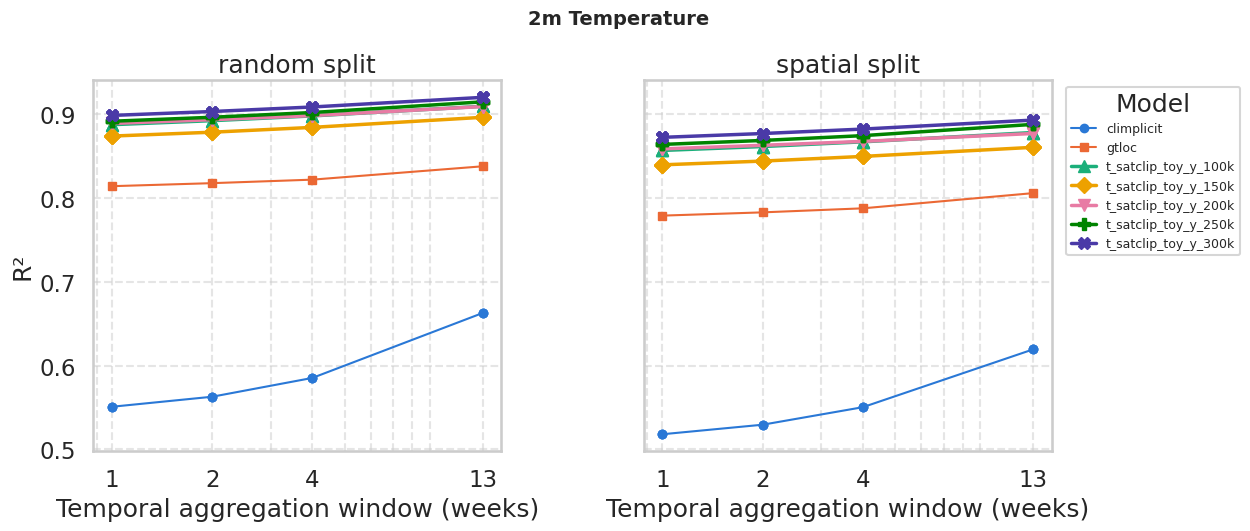

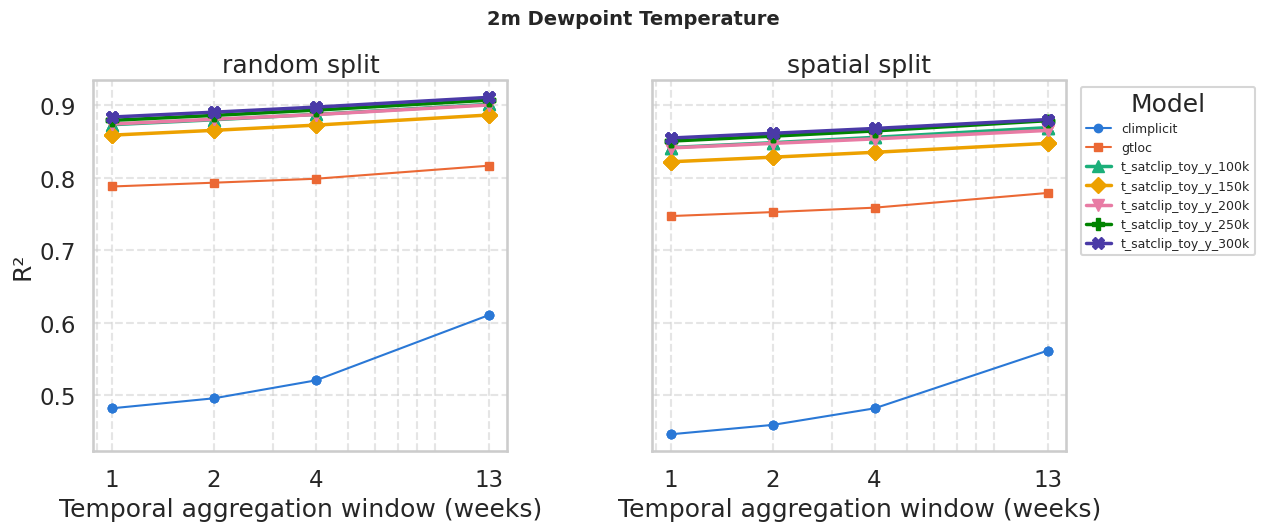

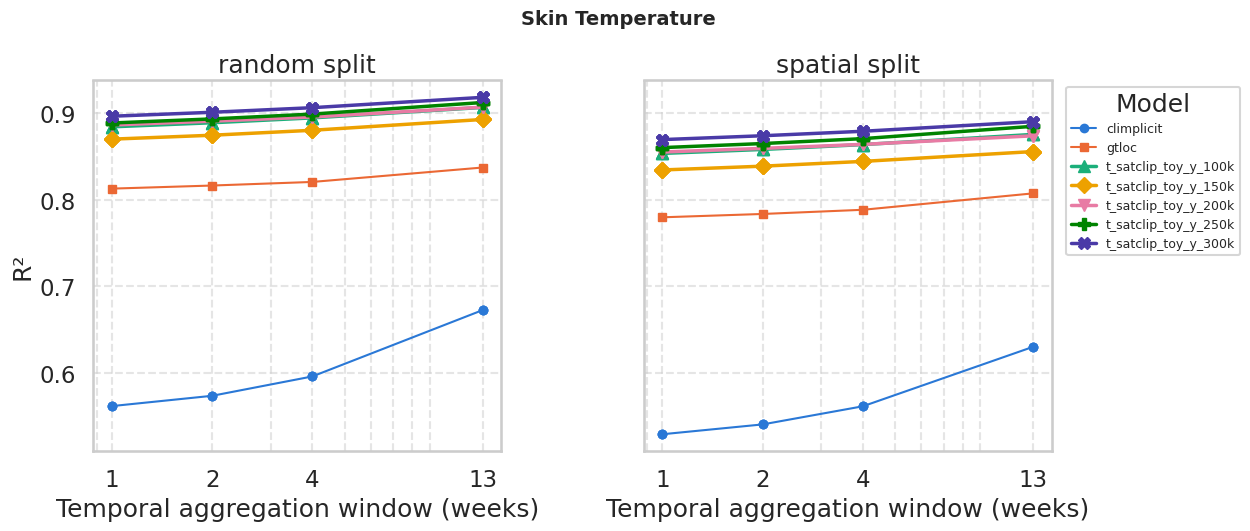

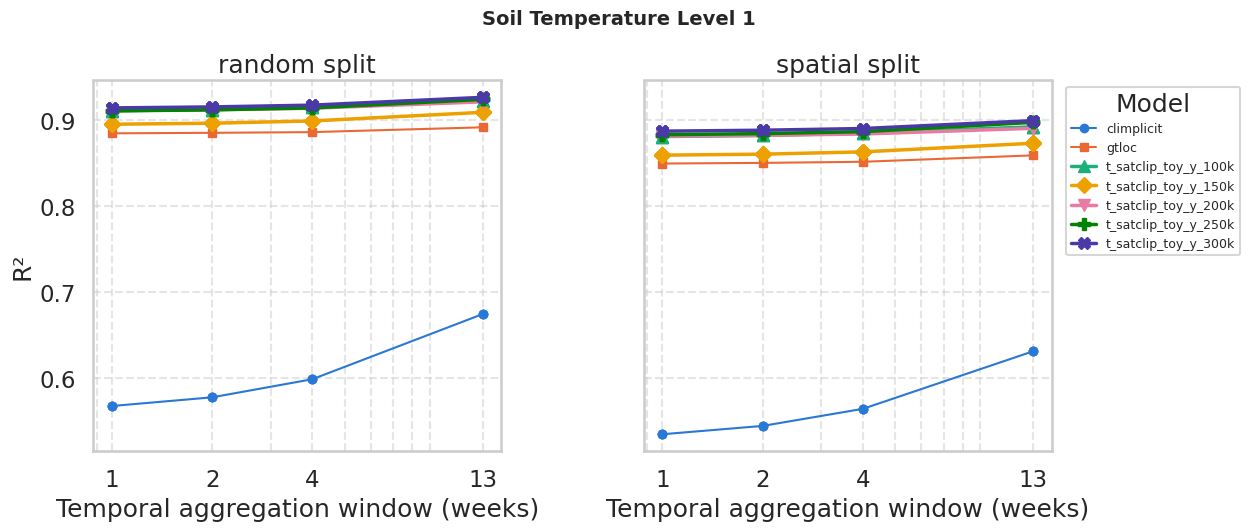

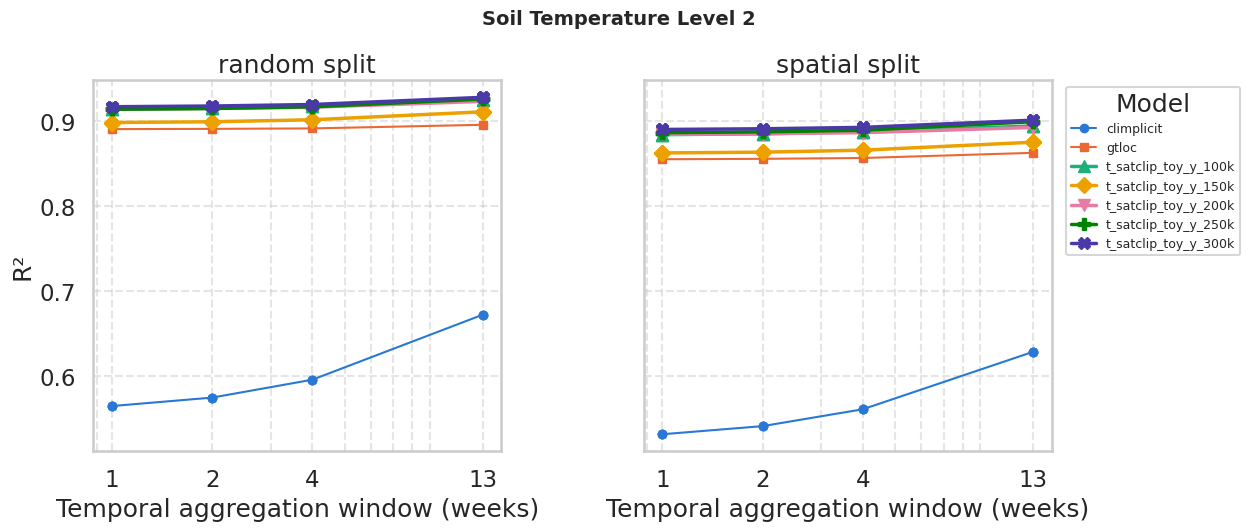

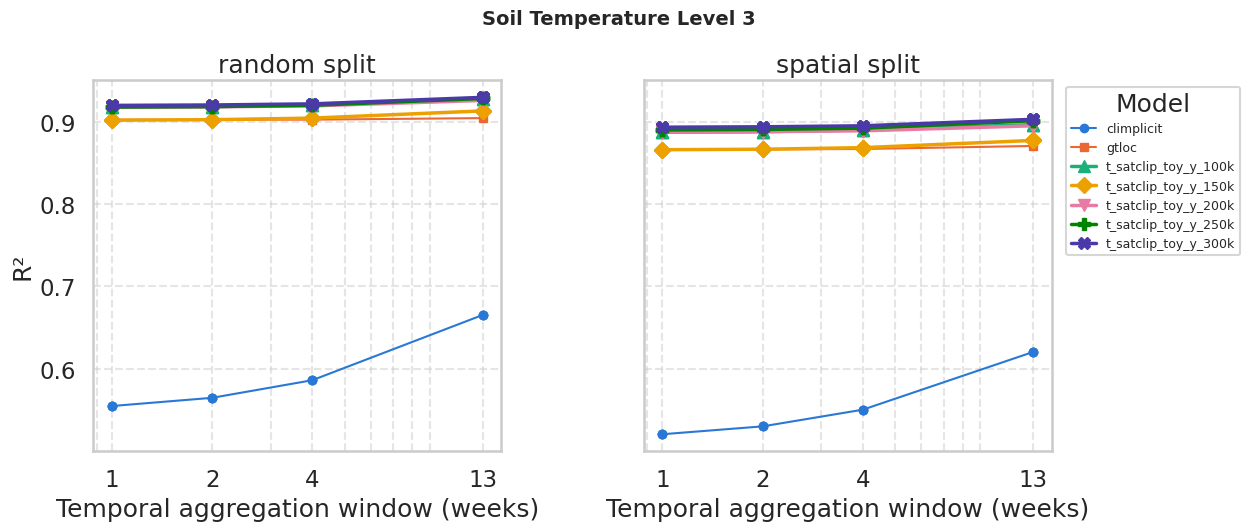

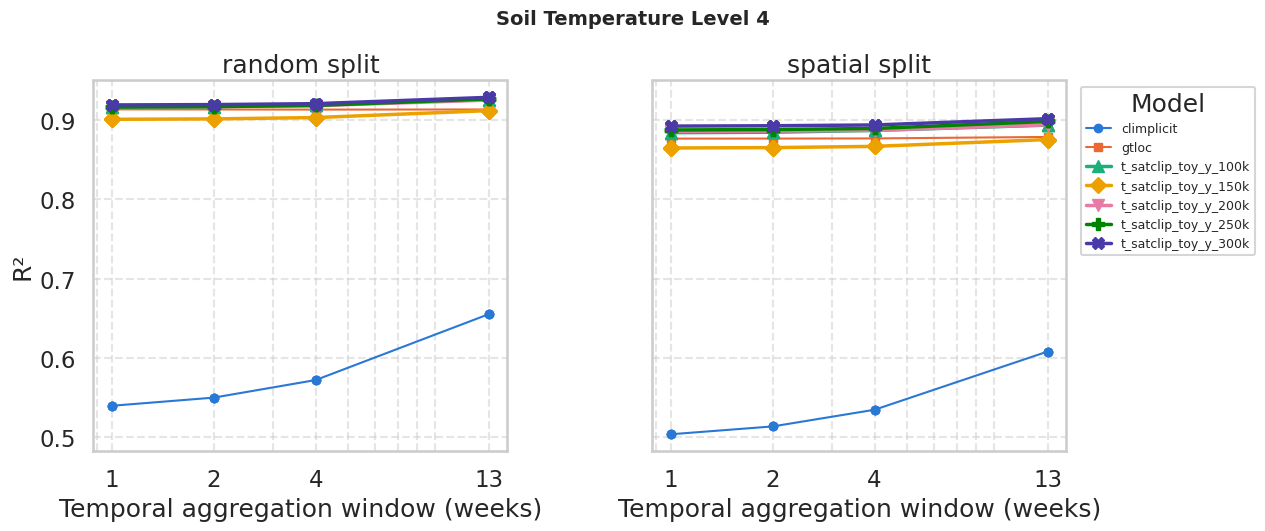

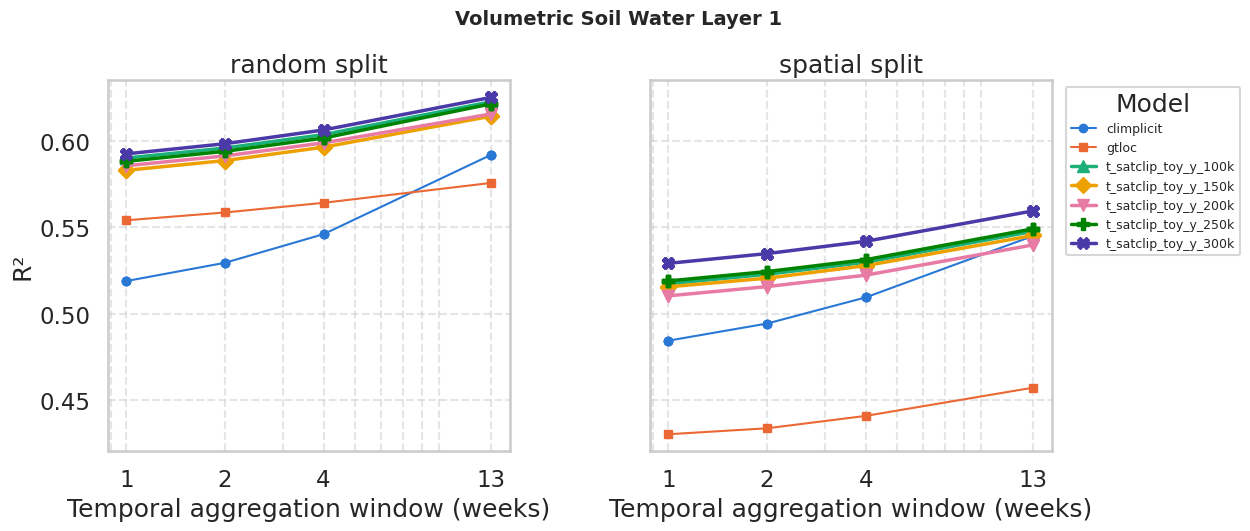

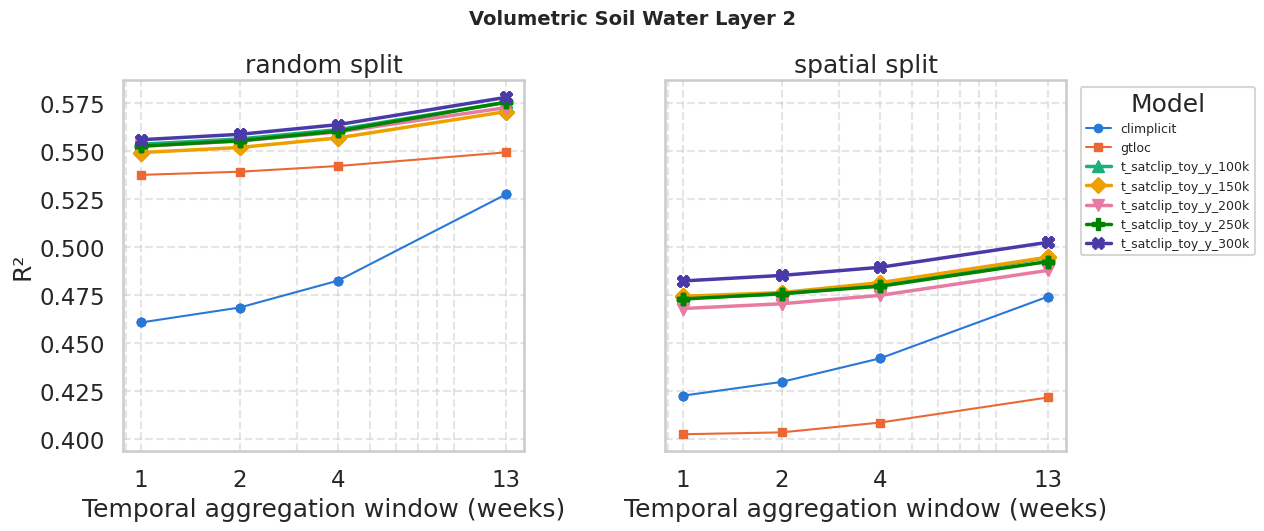

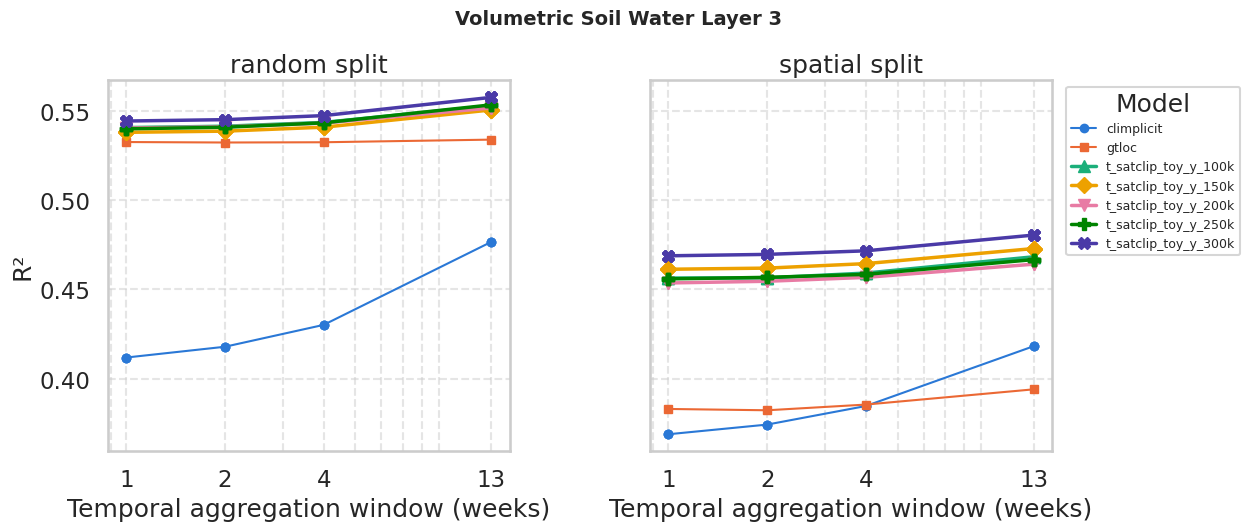

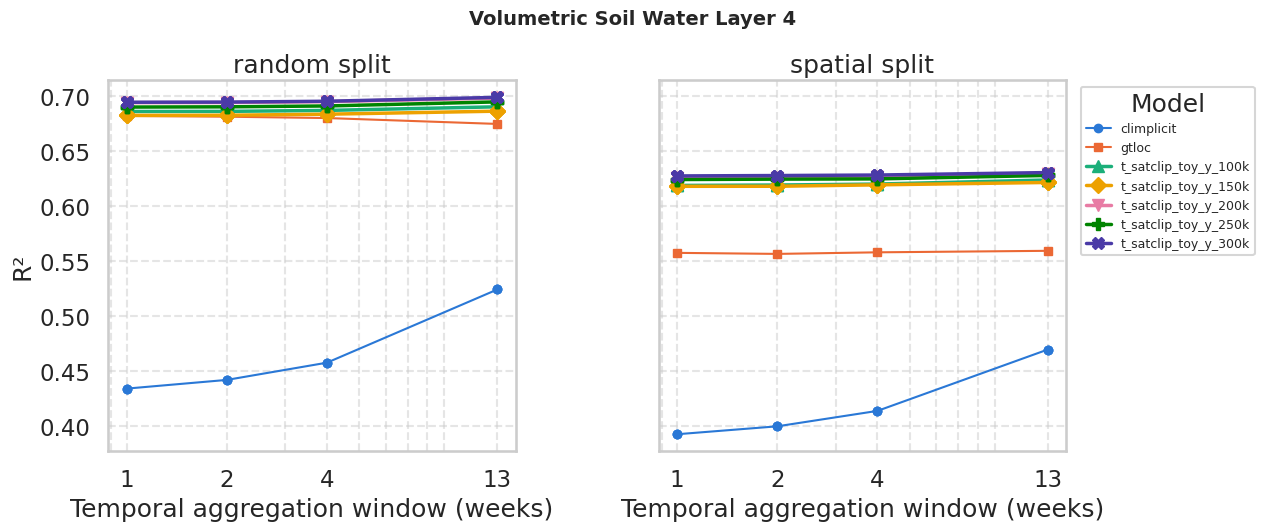

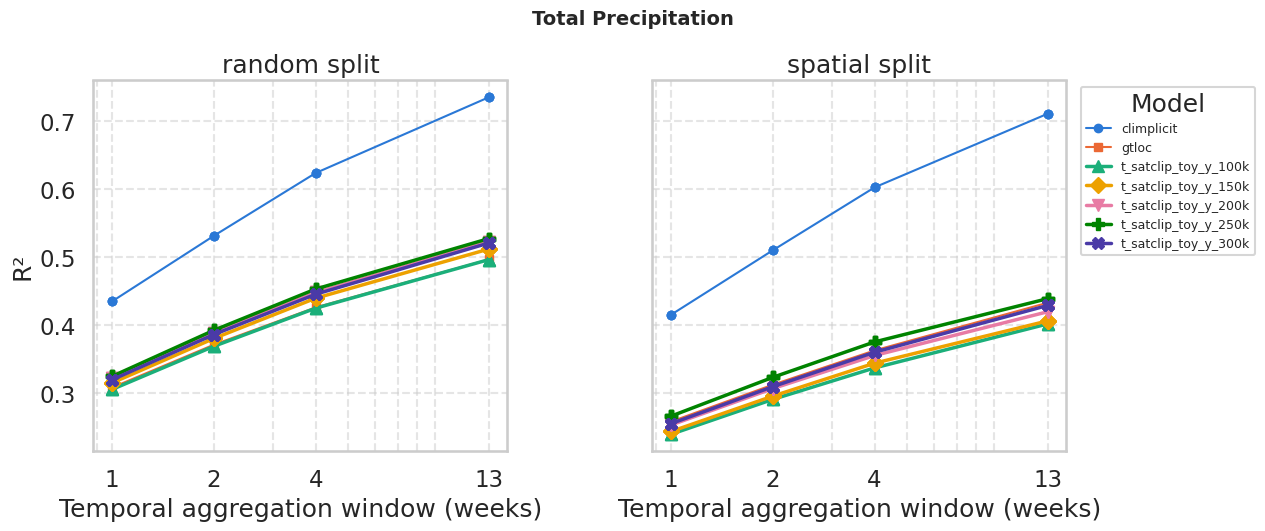

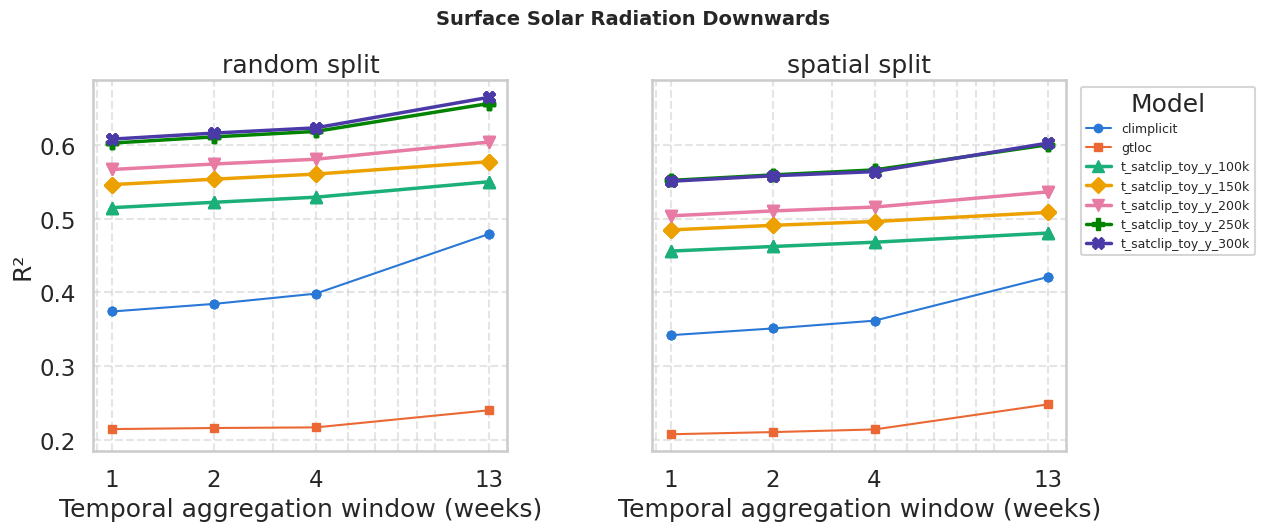

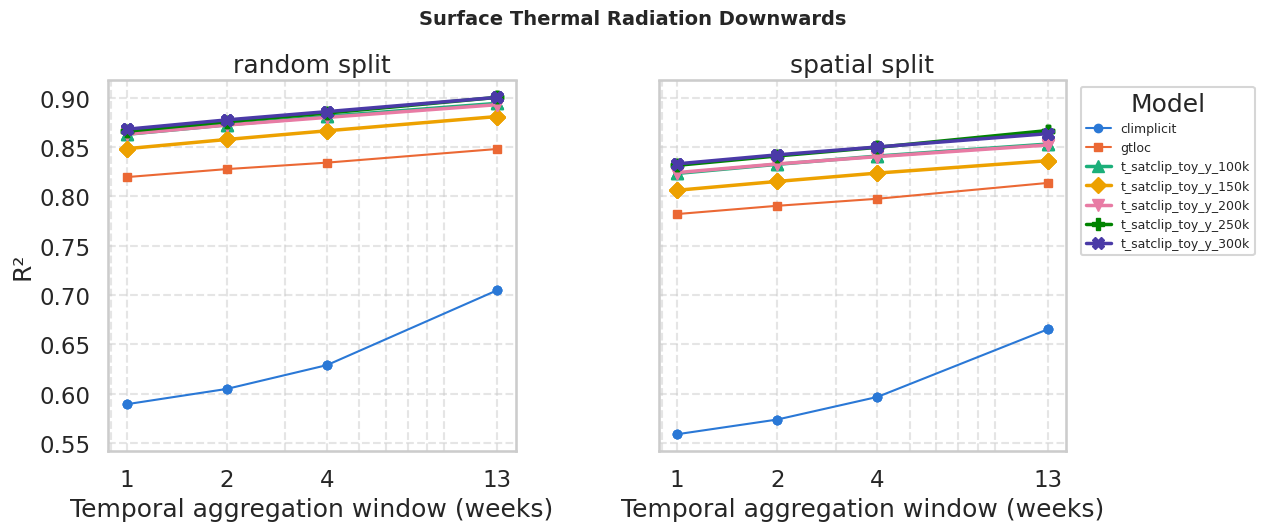

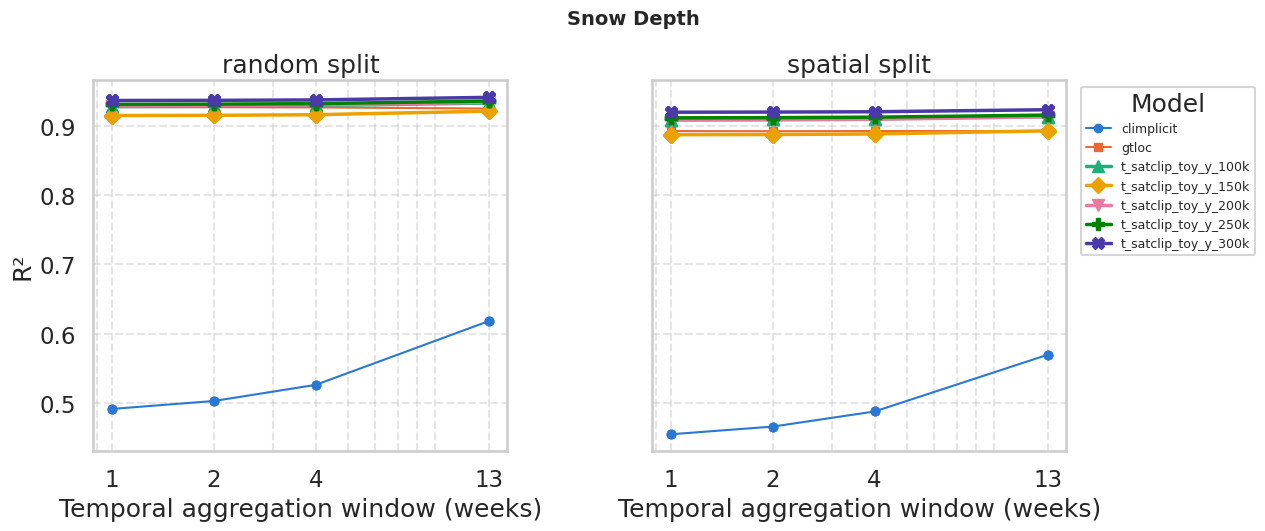

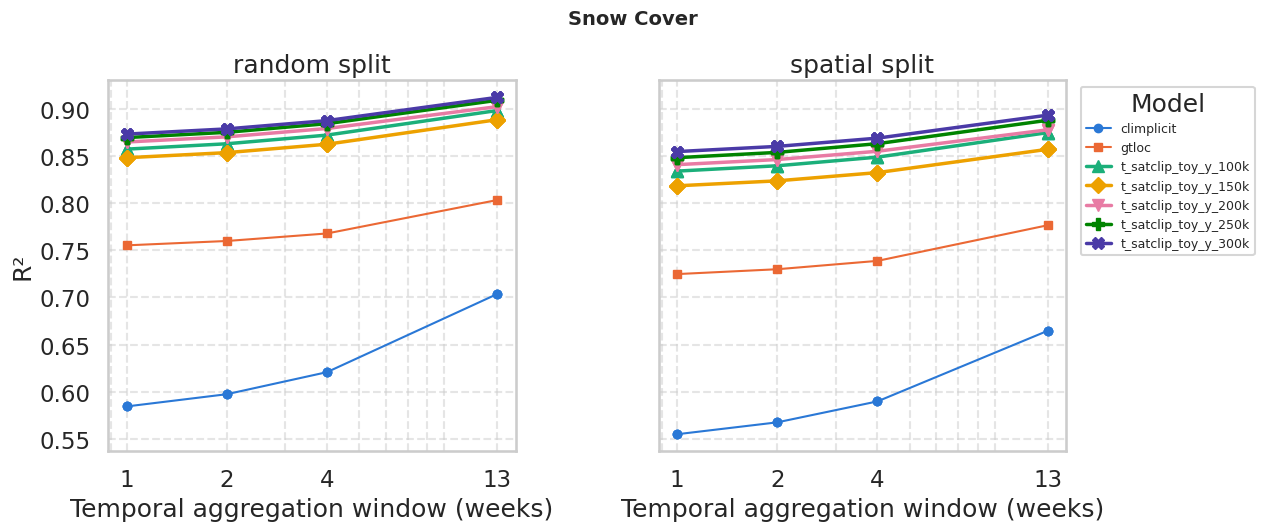

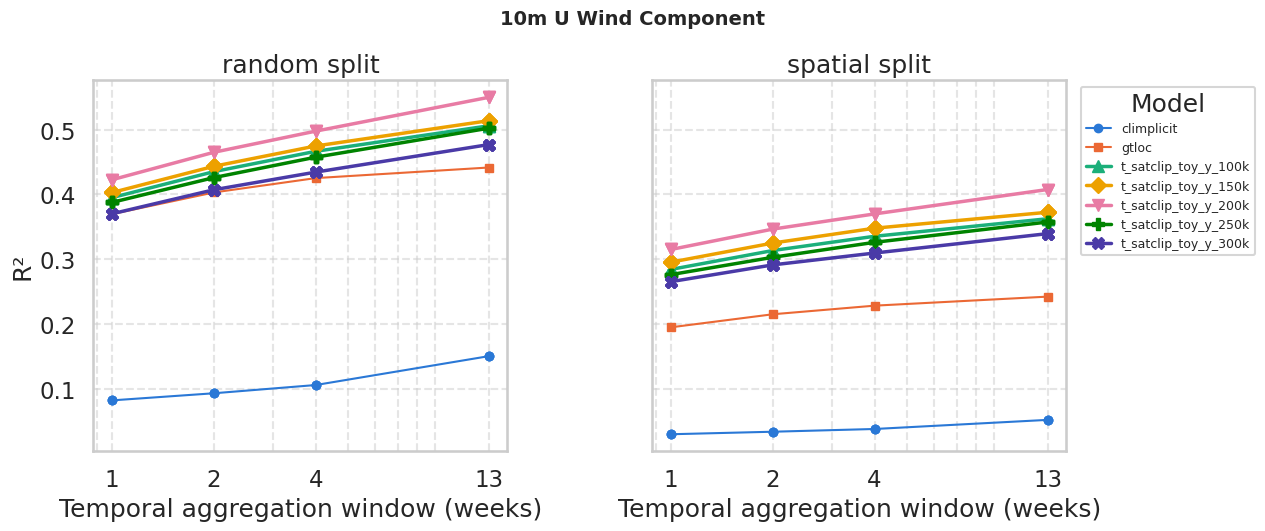

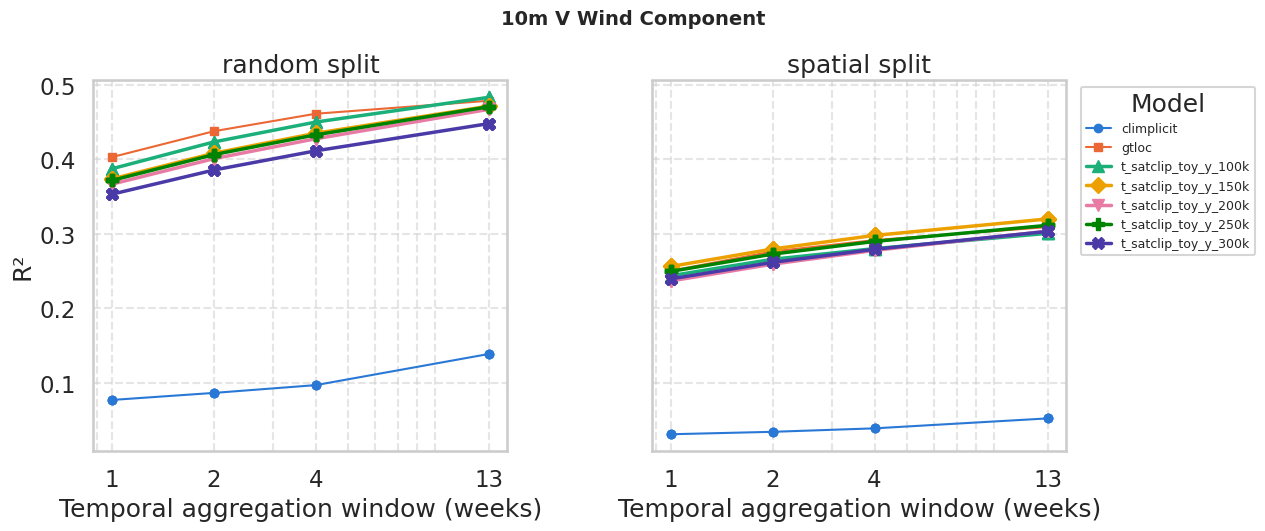

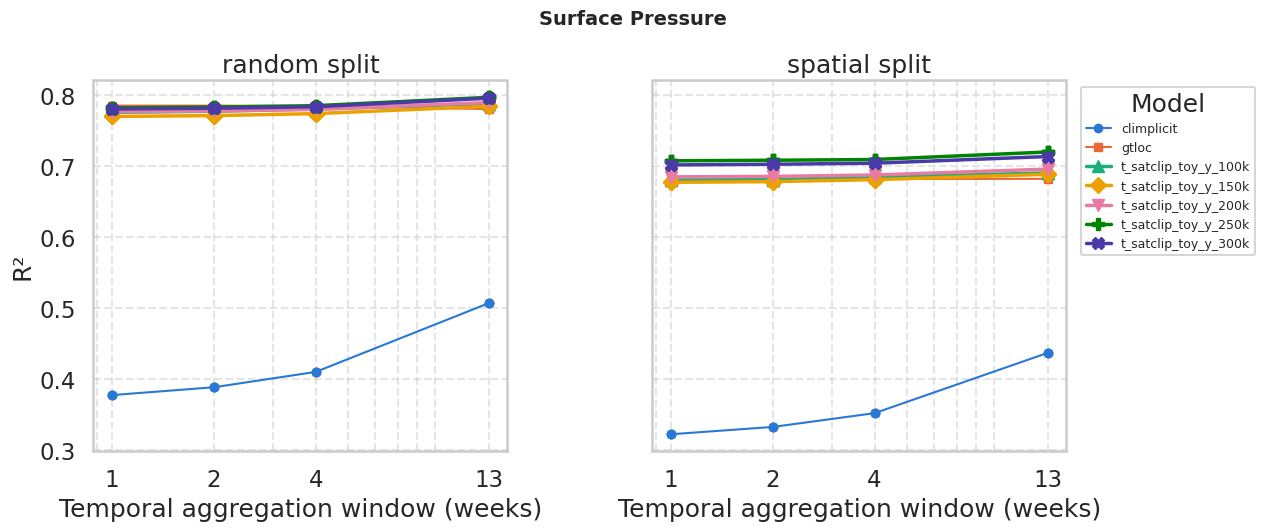

In [22]:
for task in tasks:
    plot_era5(df[df['task'] == task], models, task_labels[task], savepath=f'results/plots/era5_{task}_data.png')

In [23]:
# Take the overall average R^2 score for each split and each model
N_tasks = len(tasks)

for split in sorted(df['split'].unique()):
    split_df = df[df['split'] == split]
    avg_df = split_df.groupby('model_name')['metric_value'].mean().reset_index()
    # avg_df['metric_value'] /= N_tasks  # average over tasks
    avg_df = avg_df.sort_values('metric_value', ascending=False)
    print(f'\nAverage R² for {split} split for ERA5:')
    print(avg_df.to_string(index=False))


Average R² for random split for ERA5:
          model_name  metric_value
t_satclip_toy_y_300k      0.745700
t_satclip_toy_y_250k      0.745175
t_satclip_toy_y_200k      0.742899
t_satclip_toy_y_100k      0.737937
t_satclip_toy_y_150k      0.731270
               gtloc      0.691990
          climplicit      0.496798

Average R² for spatial split for ERA5:
          model_name  metric_value
t_satclip_toy_y_300k      0.692435
t_satclip_toy_y_250k      0.690345
t_satclip_toy_y_200k      0.683277
t_satclip_toy_y_100k      0.678149
t_satclip_toy_y_150k      0.671099
               gtloc      0.619062
          climplicit      0.455116


# Same comparison, now including aggregated (non-static) embeddings for the temporal models

For `climplicit`, `gtloc`, and `t_satclip`, compares the static embedding series above against a series
using the mean embedding over each aggregation window.

In [ ]:
agg_emb_df = pd.read_csv("/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/scripts/results/coordbench_era5_spatiotemporal_encoders_aggregated_embeddings.csv")
agg_emb_df['agg_weeks'] = agg_emb_df['dataset'].str.extract(r'-(\d+)_week').astype(int)

base_models = ['climplicit', 'gtloc', 't_satclip']
static_parts = [df[df['model_name'] == m].assign(model_name=f'{m}_static') for m in base_models]
agg_parts = [agg_emb_df[agg_emb_df['model_name'] == m].assign(model_name=f'{m}_agg') for m in base_models]
plot_df = pd.concat(static_parts + agg_parts, ignore_index=True)

temporal_models = [f'{m}_static' for m in base_models] + [f'{m}_agg' for m in base_models]
static_temporal = {f'{m}_static' for m in base_models}

# each static/agg pair shares the base model's color and marker
for m in base_models:
    marker_map[f'{m}_static'] = marker_map[f'{m}_agg'] = marker_map[m]
    MODEL_COLORS[f'{m}_static'] = MODEL_COLORS[f'{m}_agg'] = MODEL_COLORS[m]

In [ ]:
for task in tasks:
    plot_era5(
        plot_df[plot_df['task'] == task], temporal_models, task_labels[task],
        static_models=static_temporal,
        savepath=f'results/era5_{task_labels[task]}_aggregation_temporal_encoders_only.png',
    )

# Same comparison, now with the non-temporal models included

Adds the models with no temporal component (geoclip, mind, mind-small, satclip, sincos, sinr) as flat/static
reference lines alongside the aggregated-embedding series above.

In [ ]:
other_models = [m for m in models if m not in base_models]
no_temporal_parts = [df[df['model_name'] == m] for m in other_models]
plot_df_all = pd.concat(static_parts + agg_parts + no_temporal_parts, ignore_index=True)

all_plot_models = temporal_models + other_models
static_all = static_temporal | set(other_models)  # non-temporal models are always "static" too

In [ ]:
for task in tasks:
    plot_era5(
        plot_df_all[plot_df_all['task'] == task], all_plot_models, task_labels[task],
        static_models=static_all,
        savepath=f'results/era5_{task_labels[task]}_aggregation_all_models.png',
    )